In [ ]:
import pandas as pd

df = pd.read_excel('/content/Cardiovascular_Disease_DatasetCardiovascular_Disease_Dataset-1.xls')

df.head(10)

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
5,148462,24,1,1,173,0,0,0,161,0,4.7,3,2,1
6,168686,79,1,2,130,240,0,2,157,0,2.5,2,1,1
7,170498,52,1,0,127,345,0,0,192,1,4.9,1,0,0
8,188225,62,1,0,121,357,0,1,138,0,2.8,0,0,0
9,192523,61,0,0,190,181,0,1,150,0,2.9,2,0,1


In [ ]:
df.isnull().sum()

patientid            0
age                  0
gender               0
chestpain            0
restingBP            0
serumcholestrol      0
fastingbloodsugar    0
restingrelectro      0
maxheartrate         0
exerciseangia        0
oldpeak              0
slope                0
noofmajorvessels     0
target               0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patientid          1000 non-null   int64  
 1   age                1000 non-null   int64  
 2   gender             1000 non-null   int64  
 3   chestpain          1000 non-null   int64  
 4   restingBP          1000 non-null   int64  
 5   serumcholestrol    1000 non-null   int64  
 6   fastingbloodsugar  1000 non-null   int64  
 7   restingrelectro    1000 non-null   int64  
 8   maxheartrate       1000 non-null   int64  
 9   exerciseangia      1000 non-null   int64  
 10  oldpeak            1000 non-null   float64
 11  slope              1000 non-null   int64  
 12  noofmajorvessels   1000 non-null   int64  
 13  target             1000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 109.5 KB


**Comment:** There is no null value in our dataset.

### **Exploratory Data Analysis (EDA)**


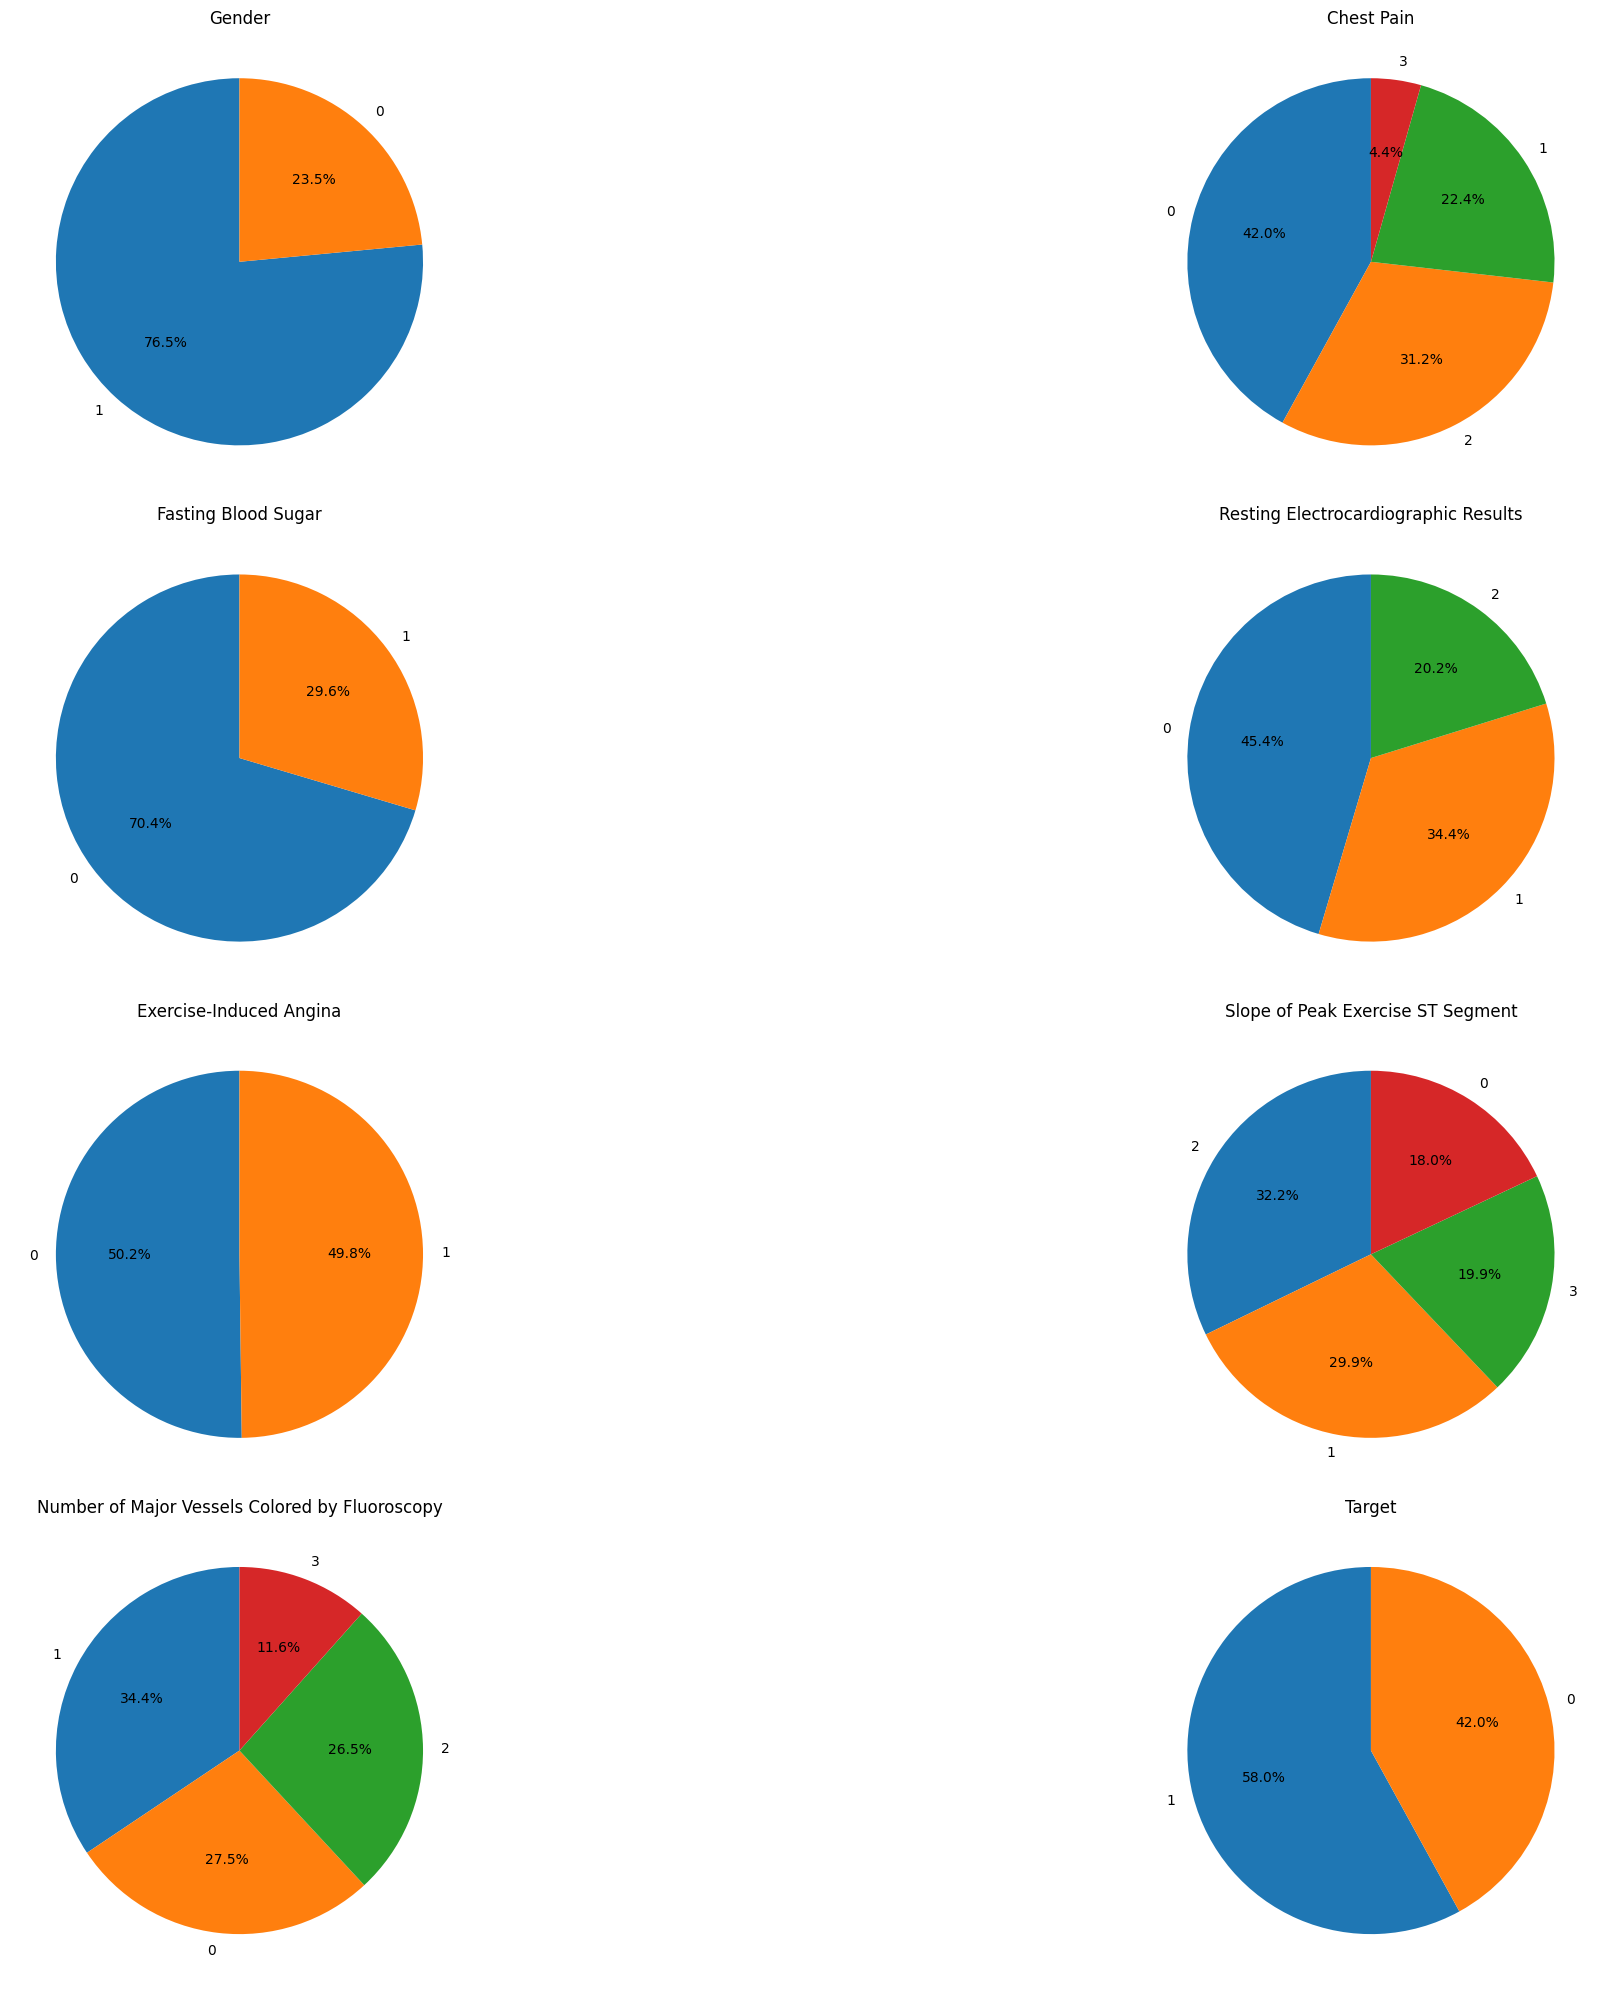

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 20))  # Adjust figsize as needed

# Subplot 1
plt.subplot(421)
df['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Gender')
plt.ylabel('')

# Subplot 2
plt.subplot(422)
df['chestpain'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Chest Pain')
plt.ylabel('')

# Subplot 3
plt.subplot(423)
df['fastingbloodsugar'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Fasting Blood Sugar')
plt.ylabel('')

# Subplot 4
plt.subplot(424)
df['restingrelectro'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Resting Electrocardiographic Results')
plt.ylabel('')

# Subplot 5
plt.subplot(425)
df['exerciseangia'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Exercise-Induced Angina')
plt.ylabel('')

# Subplot 6
plt.subplot(426)
df['slope'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Slope of Peak Exercise ST Segment')
plt.ylabel('')

# Subplot 7
plt.subplot(427)
df['noofmajorvessels'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Number of Major Vessels Colored by Fluoroscopy')
plt.ylabel('')

# Subplot 8
plt.subplot(428)
df['target'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Target')
plt.ylabel('')

plt.tight_layout()
plt.show()


**Comment:** There are 8-panel figure with pie charts representing the distributions of various categorical variables from DataFrame (df). We have adjusted the layout to prevent overlapping of the subplots and displays the figure.

### **Z-test** **between age and chestpain**

In [ ]:
import numpy as np
from scipy.stats import norm, t, ttest_ind, ttest_rel

In [ ]:
sample_mean1 = df['age'].mean()
sample_mean2 = df['chestpain'].mean()
known_variance1 = df['age'].var()
known_variance2 = df['chestpain'].var()
sample_size1 = df['age'].count()
sample_size2 = df['chestpain'].count()

In [ ]:
sample_mean1,sample_mean2,known_variance1, known_variance2,sample_size1,sample_size2

(49.242, 0.98, 319.14858458458457, 0.9085085085085085, 1000, 1000)

In [ ]:


def z_test_two_pop(sample_mean1, sample_mean2, known_variance1, known_variance2, sample_size1, sample_size2):
    z_score = (sample_mean1 - sample_mean2) / np.sqrt(known_variance1/sample_size1 + known_variance2/sample_size2)
    p_value = 2 * (1 - norm.cdf(np.abs(z_score)))
    return z_score, p_value

In [ ]:


z_score,p_value=z_test_two_pop(sample_mean1,
               sample_mean2,
               known_variance1,
               known_variance2,
               sample_size1,
               sample_size2)
z_score,p_value

(85.30835883898837, 0.0)

**Interpretation:**  Z-value of 85.31 is extremely high, suggesting a very strong departure from the null hypothesis. Given this Z-value, the p-value would be close to zero, leading to the rejection of the null hypothesis.

**p-value of Z text**

In [ ]:
alpha = 0.05
if p_value < alpha:
  print("Null Hypothesis rejected. So There is significant difference between age and chestpain.")
else:
  print("Null Hypothesis not rejected. So There no is significant difference between age and chestpain.")

Null Hypothesis rejected. So There is significant difference between age and chestpain.


**Comment:** This indicates that the observed effect or difference is statistically significant.

### **T test** **between fastingbloodsugar and restingrelectro**

In [ ]:
def t_test_equal_variances(sample1, sample2):
    t_score, p_value = ttest_ind(sample1, sample2, equal_var=True)
    return t_score, p_value

In [ ]:
sample1 = np.random.normal(df['fastingbloodsugar'])
sample2 = np.random.normal(df['restingrelectro'])

t_score, p_value = t_test_equal_variances(sample1, sample2)

print(f"t-score={t_score}, p-value={p_value}")

t-score=-7.505448572090962, p-value=9.165121466352439e-14


**t-value:** -8.57859167

**Interpretation:** t-value of -8.57859167 indicates a significant departure from the null hypothesis.t-value this large in magnitude implies that the p-value is very small.

In [ ]:
alpha = 0.05
if p_value < alpha:
  print("Null Hypothesis rejected. So There is significant difference between fastingbloodsugar and restingrelectro.")
else:
  print("Null Hypothesis not rejected. So There is no significant difference between fastingbloodsugar and restingrelectro.")

Null Hypothesis rejected. So There is significant difference between fastingbloodsugar and restingrelectro.


SO we reject the null hypothesis. This result means there is a statistically significant difference between fastingbloodsugar and restingrelectro.

### **Chi-square test for gender and exercise angia**

In [ ]:
import pandas as pd
import scipy.stats as stats

contingency_table = pd.crosstab(df['gender'], df['exerciseangia'])

contingency_table

exerciseangia,0,1
gender,,
0,107,128
1,395,370


In [ ]:

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)
print("Expected Frequencies:\n", expected)

Chi-Square Statistic: 2.439107861770847
P-value: 0.11834351477187331
Degrees of Freedom: 1
Expected Frequencies:
 [[117.97 117.03]
 [384.03 380.97]]


In [ ]:
alpha = 0.05
if p_value < alpha:
  print("Null Hypothesis rejected. So Gender and exercise angina are not independent..")
else:
  print("Null Hypothesis not rejected. So Gender and exercise angina are independent..")

Null Hypothesis not rejected. So Gender and exercise angina are independent..


**Interpretation:** Chi-square value of 2.439 is relatively low and p value is greater than alpha and does not provide sufficient evidence to reject the null hypothesis. This suggests that there is no significant association between Gender and exercise angina. So Gender and exercise angina are independent.

### **Correlation test**

<Axes: >

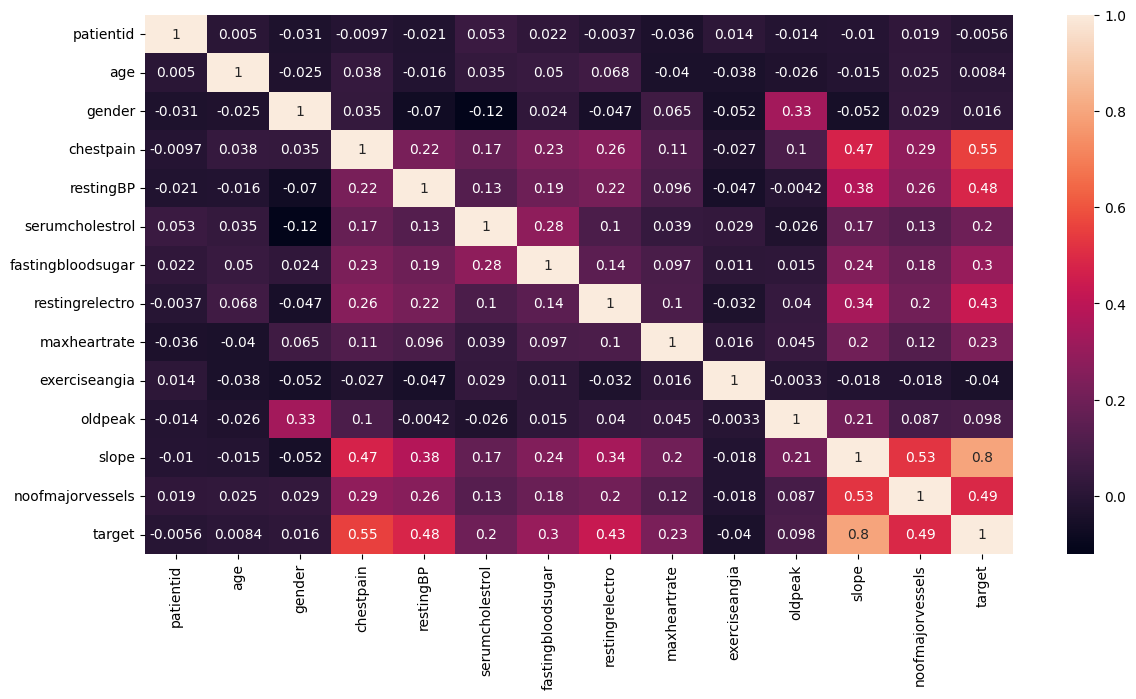

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,7))

sns.heatmap(df.corr(), annot=True)

**Comment:** There is a strong positive correlation between slope and target as the correlation coefficient (r) between these 2 variables is 0.8. Then moderate positive correlation presents between target, gender, and between slope, noofmajorvessles, and some other values. The absence of strong negative correlations indicates a positive aspect for our machine learning model.

### **Regression analysis**

In [ ]:
import statsmodels.api as sm

X = df['chestpain']
y = df['slope']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  slope   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.223
Method:                 Least Squares   F-statistic:                     287.2
Date:                Sun, 26 May 2024   Prob (F-statistic):           8.20e-57
Time:                        07:23:48   Log-Likelihood:                -1295.7
No. Observations:                1000   AIC:                             2595.
Df Residuals:                     998   BIC:                             2605.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0522      0.040     26.209      0.0

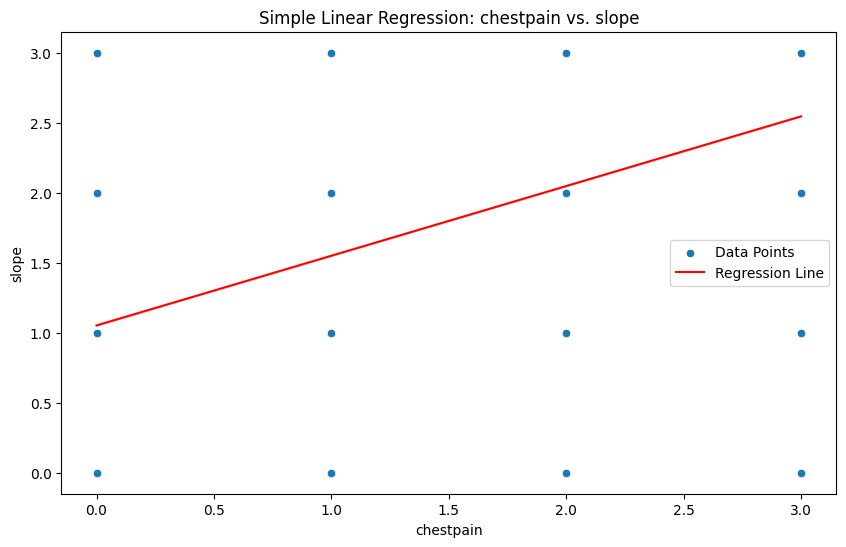

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['chestpain'], y=y, label='Data Points')
sns.lineplot(x=df['chestpain'], y=model.predict(X), color='red', label='Regression Line')
plt.xlabel('chestpain')
plt.ylabel('slope')
plt.title('Simple Linear Regression: chestpain vs. slope')
plt.legend()
plt.show()


**Interpretation:** the  r value is close to 0.5 for slope and chestpain.It indicates a moderate positive linear relationship between the two variables.the direction of the relationship is positive; That is, both variables tend to move in the same direction, clear upward trend, but the points do not lie perfectly along a straight line. There are some scatter around this trend line. So, The line of best fit, or the regression line, has a positive slope,although the relationship is not very strong.

# `**Anova Test**`

<Axes: xlabel='gender', ylabel='age'>

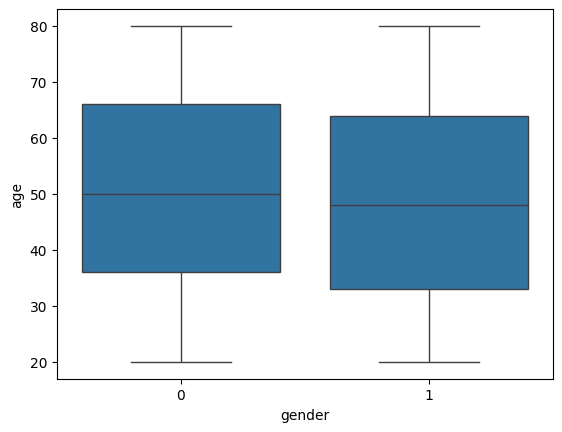

In [ ]:
sns.boxplot(x='gender' , y='age', data=df)

Here two groups are formed. So we can not perform anova test.

<Axes: xlabel='noofmajorvessels', ylabel='chestpain'>

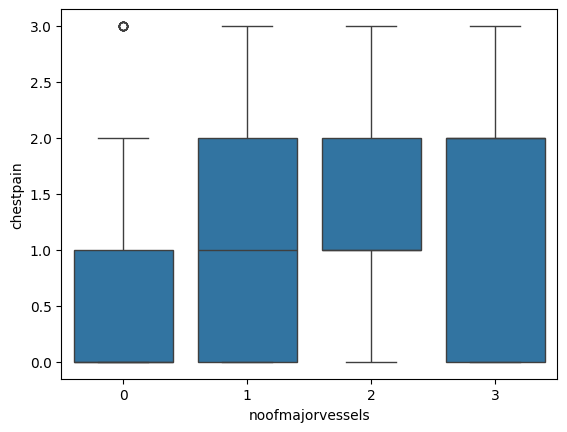

In [ ]:
sns.boxplot(x='noofmajorvessels' , y='chestpain', data=df)

In [ ]:
from statsmodels.formula.api import ols

df['chestpain'] = df['chestpain'].astype('category')

model = ols('noofmajorvessels ~ C(chestpain)' , data=df).fit()
aov_table = sm.stats.anova_lm(model , type=2)
print(aov_table)

                 df      sum_sq    mean_sq          F        PR(>F)
C(chestpain)    3.0   87.124852  29.041617  33.339956  1.546589e-20
Residual      996.0  867.591148   0.871075        NaN           NaN


In [ ]:
p_value = aov_table["PR(>F)"]["C(chestpain)"]
alpha = 0.5

if p_value < alpha:
  print(f'Since p_value < {alpha}, reject null hypothesis. There are significant difference between the groups')
else:
  print(f'Since p_value > {alpha}, the null hypothesis cannot be rejected. There are no difference between the groups')

Since p_value < 0.5, reject null hypothesis. There are significant difference between the groups


**Interpretation:** The ANOVA test results indicated that the null hypothesis was rejected. This means that there are statistically significant differences among the group means. In the context of our dataset, this could mean that different groups have different means for the variable tested. So we have to find out the groups for which the difference is occured.

### **Tukeys method**

In [ ]:
mod = sm.stats.multicomp.MultiComparison(df['noofmajorvessels'], df['chestpain'])
mod_result = mod.tukeyhsd()
print(mod_result)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      1   0.3586    0.0  0.1599 0.5573   True
     0      2   0.6882    0.0  0.5087 0.8677   True
     0      3   0.5043 0.0038  0.1238 0.8849   True
     1      2   0.3296 0.0003  0.1192 0.5399   True
     1      3   0.1457 0.7796 -0.2503 0.5417  False
     2      3  -0.1839 0.6121 -0.5706 0.2029  False
---------------------------------------------------


**Interpretation :** Here we can see there is a significant difference in the mean number of major vessels between chest pain types 0 and 1, with a mean difference of 0.3586,  between chest pain types 0 and 2, with a mean difference of 0.6882, between chest pain types 0 and 3, with a mean difference of 0.5043 and between chest pain types 1 and 2, with a mean difference of 0.3296.

# Data preparation and Feature Engineering:

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

In [ ]:
data=df

In [ ]:
data.head(2000)

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [ ]:
data.columns

Index(['patientid', 'age', 'gender', 'chestpain', 'restingBP',
       'serumcholestrol', 'fastingbloodsugar', 'restingrelectro',
       'maxheartrate', 'exerciseangia', 'oldpeak', 'slope', 'noofmajorvessels',
       'target'],
      dtype='object')

In [ ]:
import pandas as pd

# Read the Excel file into a DataFrame

# Handle missing values
data =  pd.read_excel('/content/Cardiovascular_Disease_Dataset-1.xls')
for column in data.columns:
    if data[column].dtype == 'object':
        data[column] = data[column].fillna(data[column].mode()[0])
    else:
        data[column] = data[column].fillna(data[column].mean())



In [ ]:
label_encoders = {}
for column in data.columns:
    if data[column].dtype == 'object':
        le = LabelEncoder()
        data[column] = le.fit_transform(data[column])
        label_encoders[column] = le


In [ ]:
label_encoders

{}

In [ ]:
correlation_matrix = data.corr()
correlation_matrix

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
patientid,1.000000,0.004978,-0.031263,-0.009679,-0.020926,0.053464,0.022331,-0.003667,-0.036486,0.014338,-0.013825,-0.010128,0.019465,-0.005637
age,0.004978,1.000000,-0.024717,0.037731,-0.016126,0.035439,0.049732,0.067736,-0.040092,-0.037581,-0.026020,-0.015334,0.025407,0.008356
gender,-0.031263,-0.024717,1.000000,0.035402,-0.069727,-0.120759,0.023560,-0.046634,0.064606,-0.051746,0.331457,-0.051957,0.029376,0.015769
chestpain,-0.009679,0.037731,0.035402,1.000000,0.222267,0.174731,0.232059,0.256316,0.114496,-0.027376,0.101345,0.472731,0.285156,0.554228
restingBP,-0.020926,-0.016126,-0.069727,0.222267,1.000000,0.126523,0.192063,0.219887,0.095569,-0.046545,-0.004225,0.376711,0.263194,0.482387
serumcholestrol,0.053464,0.035439,-0.120759,0.174731,0.126523,1.000000,0.278337,0.101767,0.038967,0.029422,-0.025910,0.165569,0.132419,0.195340
fastingbloodsugar,0.022331,0.049732,0.023560,0.232059,0.192063,0.278337,1.000000,0.143982,0.096528,0.011356,0.015311,0.242734,0.182246,0.303233
restingrelectro,-0.003667,0.067736,-0.046634,0.256316,0.219887,0.101767,0.143982,1.000000,0.099991,-0.032489,0.040291,0.343280,0.204684,0.426837
maxheartrate,-0.036486,-0.040092,0.064606,0.114496,0.095569,0.038967,0.096528,0.099991,1.000000,0.015536,0.044614,0.201515,0.122763,0.228343
exerciseangia,0.014338,-0.037581,-0.051746,-0.027376,-0.046545,0.029422,0.011356,-0.032489,0.015536,1.000000,-0.003296,-0.017783,-0.017513,-0.039874


In [ ]:
high_corr = correlation_matrix.index[correlation_matrix['target'] > 0.5]  # arbitrary threshold
high_corr


Index(['chestpain', 'slope', 'target'], dtype='object')

In [ ]:
# Normalize or scale continuous variables
scaler = MinMaxScaler()  # or use StandardScaler() for models like SVM
continuous_columns = [col for col in data.columns if data[col].dtype in ['float64', 'int64']]
data[continuous_columns] = scaler.fit_transform(data[continuous_columns])


In [ ]:
y = data['target']
X = data.drop('target', axis=1)


In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

Accuracy: 0.985


**Accuracy:** 0.98

**Interpretation:** The Random Forest model has an accuracy of 98%, indicating that it correctly classifies 98% of the instances in our test dataset. This is a very high accuracy, suggesting that the model performs exceptionally well.

# Train Support Vector Machine (SVM)

In [ ]:
# Support Vector Machine (SVM)
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svm ))

Accuracy: 0.975


**Accuracy**: 0.975

**Interpretation:** The SVM model has an accuracy of 97.5%, which is also very high and close to the performance of the Random Forest model. This suggests that SVM is also a strong performer for our dataset.

In [ ]:
nn_model = MLPClassifier(hidden_layer_sizes=(1000,), activation='relu', solver='adam', max_iter=300)
nn_model.fit(X_train, y_train)
y_pred_nn = nn_model.predict(X_test)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


# Train XGBoost

In [ ]:
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb ))


Accuracy: 0.97


**Accuracy:** 0.97

**Interpretation:** The XGBoost model achieves an accuracy of 97%. While slightly lower than Random Forest and SVM, it still indicates very good performance, making it a reliable model for our dataset.

# Train Logistic Regression

In [ ]:
# Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr ))

Accuracy: 0.97


**Accuracy:** 0.97

**Interpretation:** The Logistic Regression model has an accuracy of 97%, which is on par with XGBoost and slightly lower than Random Forest and SVM. This demonstrates that Logistic Regression is also effective for this classification task.

# Evaluation function to print the metrics

In [ ]:
# Evaluation function to print the metrics
def evaluate_model(y_test, y_pred, model_name):
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    print(f"Model: {model_name}")
    print(confusion_matrix(y_test, y_pred))
    print(f"{model_name} Performance:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}\n")


# Evaluating all models:

#Random Forest
evaluate_model(y_test, y_pred_rf, 'Random Forest')


Model: Random Forest
[[ 81   2]
 [  1 116]]
Random Forest Performance:
Accuracy: 0.9850
Precision: 0.9854
Recall: 0.9837
F1-Score: 0.9845



**Interpretation:** The Random Forest model has the highest accuracy (98.50%), which indicates that it is the most effective in classifying the instances correctly. Both precision (98.54%) and recall (98.37%) are very high, suggesting that the model is excellent at identifying positive instances while also minimizing false positives and false negatives. The F1-Score (98.45%) confirms this balance.

In [ ]:
# Support Vector Machine (SVM)
evaluate_model(y_test, y_pred_svm, 'SVM')

Model: SVM
[[ 81   2]
 [  3 114]]
SVM Performance:
Accuracy: 0.9750
Precision: 0.9735
Recall: 0.9751
F1-Score: 0.9743



**Interpretation:** The SVM model also performs very well with an accuracy of 97.50%. The precision (97.35%) and recall (97.51%) values are high, indicating good performance in identifying positive cases and maintaining low false positives. The F1-Score (97.43%) shows a good balance between precision and recall.

In [ ]:
# Logistic Regression
evaluate_model(y_test, y_pred_lr, 'Logistic Regression')

Model: Logistic Regression
[[ 81   2]
 [  4 113]]
Logistic Regression Performance:
Accuracy: 0.9700
Precision: 0.9678
Recall: 0.9709
F1-Score: 0.9692



**Interpretation:** Logistic Regression has an accuracy of 97.00%, similar to XGBoost. The precision (96.78%) and recall (97.09%) indicate good performance, but it has a slightly higher false negative count (4) compared to Random Forest and SVM. The F1-Score (96.92%) shows that it maintains a good balance between precision and recall.

In [ ]:
# Neural Network
evaluate_model(y_test, y_pred_nn, 'Neural Network')

Model: Neural Network
[[ 79   4]
 [  3 114]]
Neural Network Performance:
Accuracy: 0.9650
Precision: 0.9648
Recall: 0.9631
F1-Score: 0.9639



**Interpretation:** The Neural Network model has an accuracy of 96.50%, slightly lower than Random Forest and SVM. The precision (96.48%) and recall (96.31%) are still high, but it has more false positives (4) compared to Random Forest and SVM. The F1-Score (96.39%) indicates a good balance but slightly lower performance compared to the top models.

In [ ]:
# XGBoost
evaluate_model(y_test, y_pred_xgb, 'XGBoost')

Model: XGBoost
[[ 79   4]
 [  2 115]]
XGBoost Performance:
Accuracy: 0.9700
Precision: 0.9708
Recall: 0.9674
F1-Score: 0.9690



**Interpretation:** XGBoost has an accuracy of 97.00%, which is quite high. The precision (97.08%) and recall (96.74%) are also high, showing that the model performs well in classifying positive instances while keeping false positives and false negatives low. The F1-Score (96.90%) reflects this balanced performance.

# SHapley Additive exPlanations (SHAP)

In [ ]:
!pip install shap

In [ ]:
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# Understanding the SHAP Force Plot

The SHAP (SHapley Additive exPlanations) force_plot is an effective visualization tool for understanding the impact of each feature on a model's prediction for a single observation. It illustrates how each feature contributes, either positively or negatively, to the final prediction relative to the average prediction (baseline).
Here’s a breakdown of the key components of a SHAP force plot:
Base Value: This is the average prediction for the dataset, provided by the model over the training data. In classification, this would be the log odds of the baseline class, while in regression, it's the average outcome.
Output Value: This is the actual prediction for the specific instance being explained. It is displayed at the end of the force plot.
Features: Each feature that affects the prediction is shown as a force. Each force can either:
Push to the right (positive effect): These are features that push the model’s prediction higher than the base value. They are usually shown in red.
Push to the left (negative effect): These are features that push the model’s prediction lower than the base value. They are usually shown in blue.
Size of the Force: The size or length of each force represents the magnitude of that feature’s impact on the prediction. Larger forces have a more significant impact.

In [ ]:
# Train the model
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

shap.initjs()
# Create the SHAP explainer and calculate SHAP values
explainer_xgb = shap.TreeExplainer(xgb_model)
shap_values_xgb = explainer_xgb.shap_values(X_train)

# Visualize the first prediction's explanation
shap.force_plot(explainer_xgb.expected_value, shap_values_xgb[0,:], X_train.iloc[0,:])

Interpretation : In the plot above, the bold 7.95 is the model’s score for this observation.he features that were important to making the prediction for this observation are shown in red and blue, with red representing features that pushed the model score higher, and blue representing features that pushed the score lower.

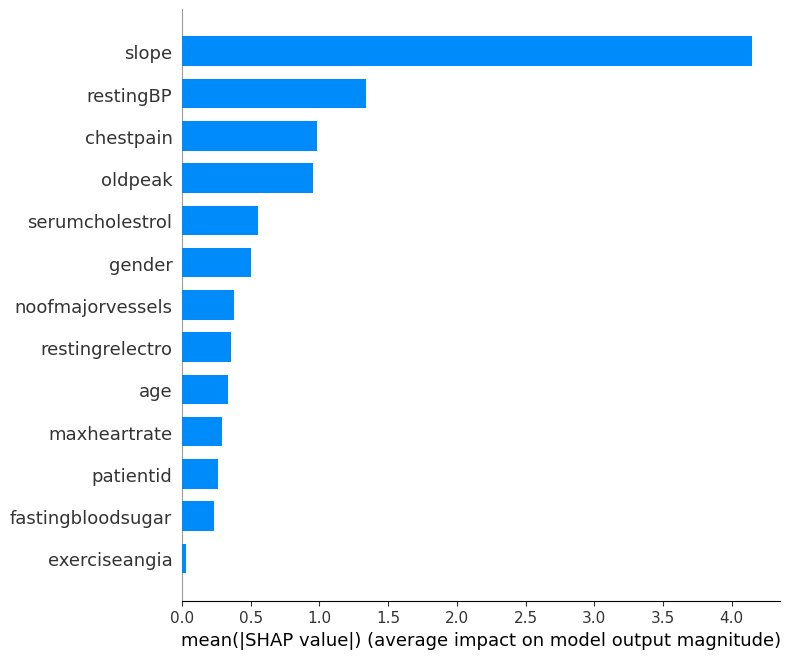

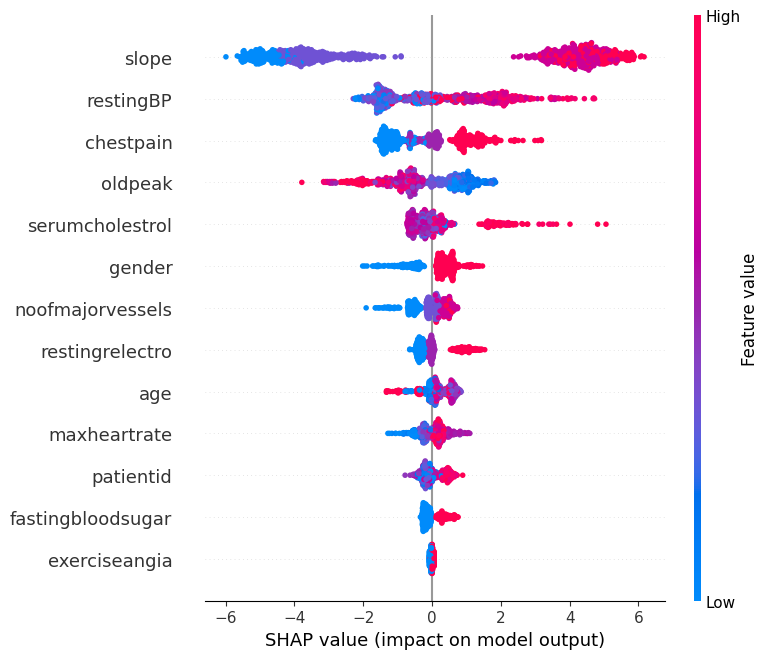

In [ ]:
# Assuming X_train and y_train are already defined and preprocessed
# Train the XGBoost model
xgb_model = xgb.XGBClassifier(random_state=42, verbosity=1, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# Create the SHAP explainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train)

# Generate SHAP summary plot
shap.summary_plot(shap_values, X_train, plot_type="bar")

# You can also create a detailed SHAP summary plot (beeswarm plot) to see the distribution
shap.summary_plot(shap_values, X_train, plot_type='dot')




Interpretation : The results show that “solpe,” “restingBP,” and “Chestpain” play major roles in determining the results.

# Examine how changes in a feature change the model’s prediction

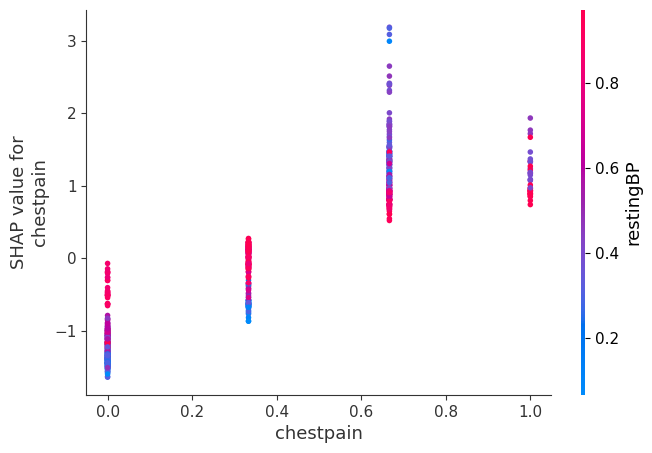

In [ ]:
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# Assuming the XGBoost model and data are already defined and loaded: xgb_model, X_train

# Create the SHAP explainer and calculate SHAP values
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train)

# Plot the SHAP dependence plot for a specific feature
feature_name = 'chestpain'

# Select a feature for coloring to show interactions; if not sure, let SHAP choose one
interaction_index = 'auto'

shap.dependence_plot(ind=feature_name, shap_values=shap_values, features=X_train, interaction_index=interaction_index)

plt.show()


Interpretation : From the graph, it looks like high values of chest pain tend to correspond with positive SHAP values. This suggests that chest pain is a feature that increases the model’s prediction of the target variable. However, without more context about the model it’s difficult to say definitively what this means.

# Local Interpretable Model-agnostic Explanations (LIME)

In [ ]:
!pip install lime

# Understanding LIME Plot Components

Prediction: The overall prediction of the classifier for the specific instance being explained. This is usually shown at the top of the plot.

Local Model: LIME creates a simple model (like a linear model) that approximates the behavior of the complex model near the instance being explained. This local model is used to interpret the result.

Feature Contributions:

Positive Contributions (Green Bars): Features that push the model’s prediction in the positive direction (towards the predicted class). The length of the bar indicates the strength of the contribution.
Negative Contributions (Red Bars): Features that push the model’s prediction in the negative direction (away from the predicted class). Again, the length of the bar reflects the magnitude of the impact.
Base Line/Intercept: This is the starting point of the prediction, assuming no features are contributing. It's akin to a baseline from which the contributions of all features are measured.

In [ ]:
import xgboost as xgb
from lime import lime_tabular
import numpy as np

# Assume X_train, y_train are already defined and the XGBoost model is trained:
# xgb_model = xgb.XGBClassifier(...)
# xgb_model.fit(X_train, y_train)

# Create a LIME explainer object
explainer = lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['Negative', 'Positive'],  # Adjust based on your target classes
    mode='classification'
)

# Select the instance to explain
i = 2  # Index of the instance in the test set
instance = X_train.iloc[i]

# Generate explanations
exp = explainer.explain_instance(
    data_row=instance,
    predict_fn=xgb_model.predict_proba
)

# Visualize the explanation
exp.show_in_notebook(show_table=True, show_all=False)

# Explanation:
# This will generate an HTML output showing the contribution of each feature to the prediction of the selected instance.


Interpretation : We can observe that predicted Positive with 100% confidence. The reasons that led the model to make this decision is because:
The slope level is more than 99
and the noofmajorvessels is more than 60.

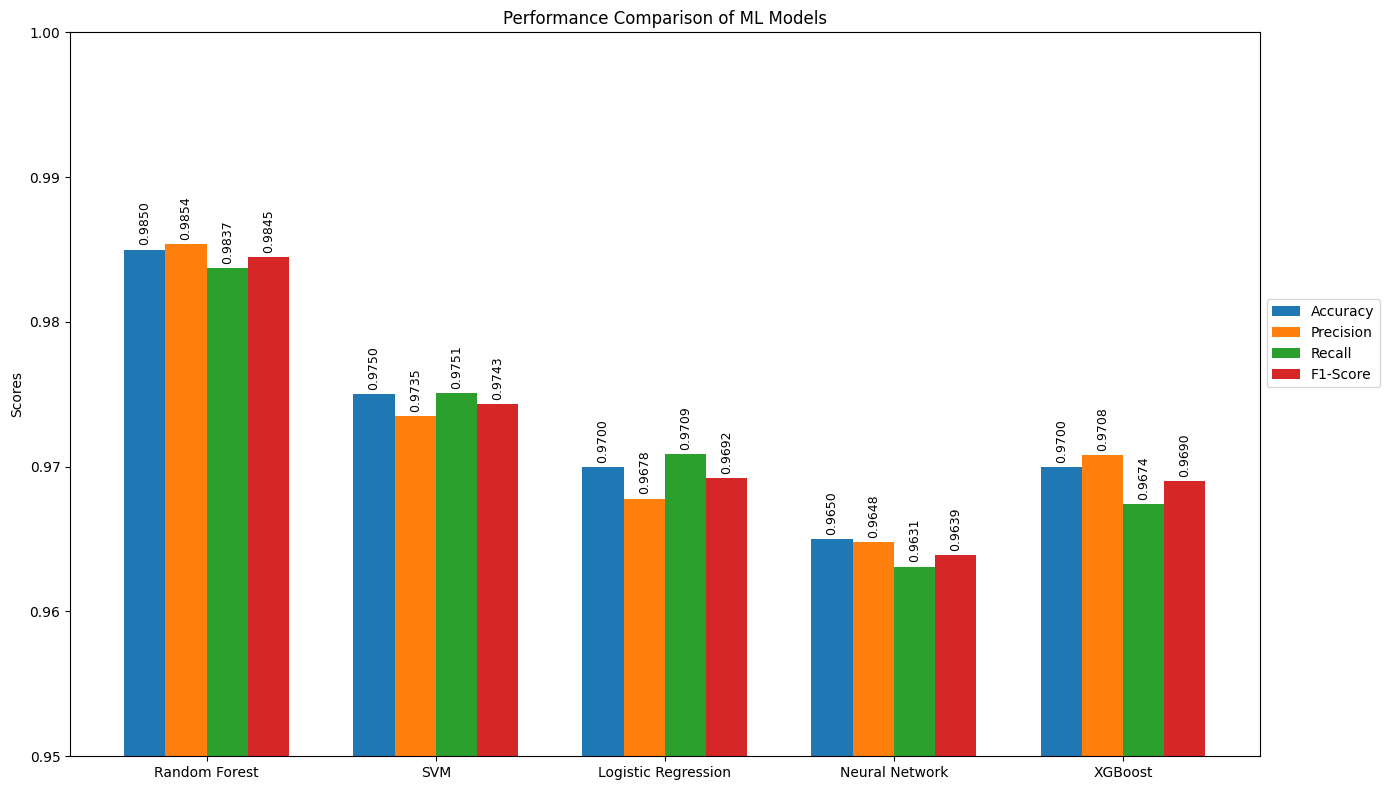

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ডেটা সেট করা
models = ['Random Forest', 'SVM', 'Logistic Regression', 'Neural Network', 'XGBoost']
accuracy = [0.9850, 0.9750, 0.9700, 0.9650, 0.9700]
precision = [0.9854, 0.9735, 0.9678, 0.9648, 0.9708]
recall = [0.9837, 0.9751, 0.9709, 0.9631, 0.9674]
f1_score = [0.9845, 0.9743, 0.9692, 0.9639, 0.9690]

x = np.arange(len(models))
width = 0.18  # বারগুলোর প্রস্থ

fig, ax = plt.subplots(figsize=(14, 8))

# প্রতিটি মেট্রিকের জন্য আলাদা বার প্লট করা
rects1 = ax.bar(x - 1.5*width, accuracy, width, label='Accuracy', color='#1f77b4')
rects2 = ax.bar(x - 0.5*width, precision, width, label='Precision', color='#ff7f0e')
rects3 = ax.bar(x + 0.5*width, recall, width, label='Recall', color='#2ca02c')
rects4 = ax.bar(x + 1.5*width, f1_score, width, label='F1-Score', color='#d62728')

# লেবেল এবং টাইটেল যোগ করা
ax.set_ylabel('Scores')
ax.set_title('Performance Comparison of ML Models')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend(loc='lower left', bbox_to_anchor=(1, 0.5))

# পার্থক্য স্পষ্টভাবে বোঝার জন্য y-axis কিছুটা জুম করা
ax.set_ylim(0.95, 1.0)

# বারের উপরে ভ্যালু দেখানোর জন্য ফাংশন
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, rotation=90)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

plt.tight_layout()
plt.show()